# Temporal volatility forecasting

This notebook presents the same tested core used by `volatility-lab`.
**All newly executed data are synthetic.** The archived AAPL results are
shown separately with their losing periods. Run from the repository root
after installing `.[notebook]`. No key, account or download is needed.

In [1]:
import pandas as pd
from IPython.display import display
from predicting_volatility_data import synthetic_prices
from predicting_volatility_experiment import ExperimentConfig, make_plan, run_experiment, plot_final
config = ExperimentConfig.from_json('examples/synthetic.json')
prices = synthetic_prices(n=900, seed=config.seed)
print('Input:', prices.metadata['data_kind'], '| Units:', prices.metadata['currency'])

Input: synthetic | Units: SYNTHETIC_UNITS


## Define the target and availability

After the close at t is known, predict
$y_t=\mathrm{std}(r_{t+1},\ldots,r_{t+h})$, with
$r_t=P_t/P_{t-1}-1$ and `ddof=1`. Each target uses prices t through t+h.
The horizon counts source observations, not calendar days. Values remain
return fractions per observation: 0.01 means 1%, without annualization.

The fixture has predeclared variance regimes and artificial weekday dates.
It is not an observed market dataset or a calibrated investment model.

In [2]:
display(pd.Series({
    'first_origin': prices.close.index.min(), 'last_origin': prices.close.index.max(),
    'observations': len(prices.close), 'horizon': config.horizon, 'seed': config.seed,
    'prices_available_by_forecast': bool((prices.available_at <= prices.close.index).all())
}))

first_origin                    2000-01-03 00:00:00+00:00
last_origin                     2003-06-13 00:00:00+00:00
observations                                          900
horizon                                                10
seed                                                   42
prices_available_by_forecast                         True

## Fix the protocol before fitting

A plan fixes configuration, dates, features, references and data/code hashes
without fitting. Training labels must finish strictly before the next
validation origin. The same rule separates validation/test and internal folds.
Dates are retained from the original price calendar before incomplete samples
are removed. Targets are never imputed.

In [3]:
plan = make_plan(prices, config)
display(pd.Series({key: plan['protocol'][key] for key in (
    'holdout_status', 'validation_start', 'test_start',
    'test_last_prediction', 'test_last_label_price', 'target_unit'
)}))

holdout_status                                                   synthetic
validation_start                                 2002-06-13T00:00:00+00:00
test_start                                       2002-12-06T00:00:00+00:00
test_last_prediction                             2003-05-30T00:00:00+00:00
test_last_label_price                            2003-06-13T00:00:00+00:00
target_unit              simple-return fraction per observation; sample...

## Train within each fold and audit the boundaries

Each fold fits its own `median imputation → robust scaling → MI selection →
model` pipeline. The bounded Ridge grid has four candidates and three inner
folds. XGBoost can use the same workflow through an optional dependency.
Parameters are selected only with inner CV. After reporting validation,
refit uses labels already matured before test; test labels cannot enter fit.

In [4]:
result = run_experiment(prices, config, plan)
display(result['tables']['outer_audit'])
display(result['tables']['inner_audit'])
display(result['tables']['refit_audit'])
assert result['tables']['feature_availability']['available'].all()

partition,n,first_prediction,last_prediction,last_label_price,exclusive_cutoff,separated,experiment
train,242,2000-10-23 00:00:00+00:00,2001-09-25 00:00:00+00:00,2001-10-09 00:00:00+00:00,2001-10-10 00:00:00+00:00,True,rolling_1
validation,53,2001-10-10 00:00:00+00:00,2001-12-21 00:00:00+00:00,2002-01-04 00:00:00+00:00,2002-01-07 00:00:00+00:00,True,rolling_1
test,53,2002-01-07 00:00:00+00:00,2002-03-20 00:00:00+00:00,2002-04-03 00:00:00+00:00,2002-04-04 00:00:00+00:00,True,rolling_1
train,242,2001-01-18 00:00:00+00:00,2001-12-21 00:00:00+00:00,2002-01-04 00:00:00+00:00,2002-01-07 00:00:00+00:00,True,rolling_2
validation,53,2002-01-07 00:00:00+00:00,2002-03-20 00:00:00+00:00,2002-04-03 00:00:00+00:00,2002-04-04 00:00:00+00:00,True,rolling_2
test,53,2002-04-04 00:00:00+00:00,2002-06-17 00:00:00+00:00,2002-07-01 00:00:00+00:00,2002-07-02 00:00:00+00:00,True,rolling_2
train,242,2001-04-17 00:00:00+00:00,2002-03-20 00:00:00+00:00,2002-04-03 00:00:00+00:00,2002-04-04 00:00:00+00:00,True,rolling_3
validation,53,2002-04-04 00:00:00+00:00,2002-06-17 00:00:00+00:00,2002-07-01 00:00:00+00:00,2002-07-02 00:00:00+00:00,True,rolling_3
test,53,2002-07-02 00:00:00+00:00,2002-09-12 00:00:00+00:00,2002-09-26 00:00:00+00:00,2002-09-27 00:00:00+00:00,True,rolling_3
train,607,2000-02-01 00:00:00+00:00,2002-05-29 00:00:00+00:00,2002-06-12 00:00:00+00:00,2002-06-13 00:00:00+00:00,True,final


fold,train_n,validation_n,last_train_prediction,last_train_label_price,first_validation_prediction,separated,experiment
0,52,50,2001-01-02 00:00:00+00:00,2001-01-16 00:00:00+00:00,2001-01-17 00:00:00+00:00,True,rolling_1
1,112,50,2001-03-27 00:00:00+00:00,2001-04-10 00:00:00+00:00,2001-04-11 00:00:00+00:00,True,rolling_1
2,172,60,2001-06-19 00:00:00+00:00,2001-07-03 00:00:00+00:00,2001-07-04 00:00:00+00:00,True,rolling_1
0,52,50,2001-03-30 00:00:00+00:00,2001-04-13 00:00:00+00:00,2001-04-16 00:00:00+00:00,True,rolling_2
1,112,50,2001-06-22 00:00:00+00:00,2001-07-06 00:00:00+00:00,2001-07-09 00:00:00+00:00,True,rolling_2
2,172,60,2001-09-14 00:00:00+00:00,2001-09-28 00:00:00+00:00,2001-10-01 00:00:00+00:00,True,rolling_2
0,52,50,2001-06-27 00:00:00+00:00,2001-07-11 00:00:00+00:00,2001-07-12 00:00:00+00:00,True,rolling_3
1,112,50,2001-09-19 00:00:00+00:00,2001-10-03 00:00:00+00:00,2001-10-04 00:00:00+00:00,True,rolling_3
2,172,60,2001-12-12 00:00:00+00:00,2001-12-26 00:00:00+00:00,2001-12-27 00:00:00+00:00,True,rolling_3
0,144,141,2000-08-18 00:00:00+00:00,2000-09-01 00:00:00+00:00,2000-09-04 00:00:00+00:00,True,final


experiment,n,last_label_price,exclusive_label_cutoff,separated
rolling_1,305,2002-01-04 00:00:00+00:00,2002-01-07 00:00:00+00:00,True
rolling_2,305,2002-04-03 00:00:00+00:00,2002-04-04 00:00:00+00:00,True
rolling_3,305,2002-07-01 00:00:00+00:00,2002-07-02 00:00:00+00:00,True
final,733,2002-12-05 00:00:00+00:00,2002-12-06 00:00:00+00:00,True


## Report every partition and both references

Trailing-horizon volatility and mean training volatility receive exactly
the same dates and target units. The table reports errors as fractions;
the chart multiplies volatility by 100. Synthetic metrics verify the workflow
and do not establish market performance.

partition,model,n,rmse,mae,experiment
validation,model,53,0.003430,0.002851,rolling_1
validation,trailing_volatility,53,0.003569,0.003002,rolling_1
validation,train_mean,53,0.005110,0.004634,rolling_1
test,model,53,0.002302,0.001847,rolling_1
test,trailing_volatility,53,0.002502,0.002108,rolling_1
test,train_mean,53,0.004932,0.004626,rolling_1
validation,model,53,0.002379,0.001887,rolling_2
validation,trailing_volatility,53,0.002502,0.002108,rolling_2
validation,train_mean,53,0.005864,0.005609,rolling_2
test,model,53,0.008575,0.005076,rolling_2


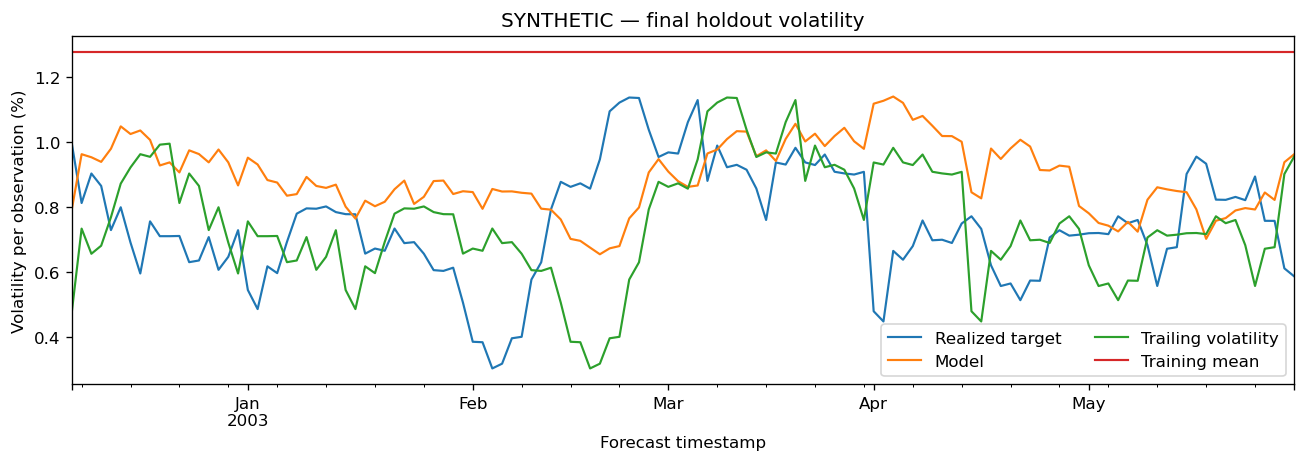

In [5]:
display(result['tables']['metrics'])
display(plot_final(result))

## Keep the historical evidence mixed

This table redisplays frozen AAPL errors, without prices or retraining.
The 24.53% improvement in final-test RMSE was one outcome. The third rolling
test and final validation were worse than trailing volatility. Adjustment
provenance and redistribution rights for that source cache were not verified.

In [6]:
historical = pd.read_csv('docs/results/aapl_historical_metrics.csv')
display(historical)

experiment,partition,model,n,rmse,mae
rolling_1,validation,model,116,0.006416,0.004891
rolling_1,validation,trailing_volatility,116,0.008162,0.006670
rolling_1,validation,train_mean,116,0.006846,0.005399
rolling_1,test,model,116,0.006848,0.005326
rolling_1,test,trailing_volatility,116,0.007011,0.005595
rolling_1,test,train_mean,116,0.007842,0.006122
rolling_2,validation,model,116,0.007113,0.005482
rolling_2,validation,trailing_volatility,116,0.007011,0.005595
rolling_2,validation,train_mean,116,0.007793,0.006096
rolling_2,test,model,116,0.004840,0.003854


## Interpretation and new research

Adjacent labels overlap inside each block; errors remain dependent. No iid
confidence claim, return, cost or alpha is inferred. The AAPL period is already
seen. New hypotheses need new predeclared test dates and selection rules.
The program cannot authenticate a supplier's timestamps or know everything
the researcher inspected elsewhere.

The CLI writes immutable versioned runs with plans, hashes, predictions and
audit tables. See `docs/method.md`, `docs/data-contract.md`, and the complete
`docs/historical-results.md`. No external data are needed to rebuild this demo.